<a href="https://colab.research.google.com/github/SNIGDHA-ms24043/IDC-PROJECT--Music-Genre-Classification/blob/main/Music_Genre_IDC_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("let's goooo")
print("music genre classification ")
print("features ")

let's goooo
music genre classification 
features 


In [ ]:
# Snigdha
'''
Roadmap
1) create table => Use audio features such as MFCC,chroma, spectral centroid, tempo and energy.=> done already
2) Start with extracted-feature CSV if audio processing is too hard.
Advanced one can use Librosa to extract features from .wav files. => Librosa is a Python library specifically designed for analyzing audio and music.
.wav is an audio file format.
3)EDA: compare tempo, spectral features and MFCC patterns across genres.
4)Classification: KNN, SVM, RandomForest, Logistic Regression.Feature scaling is important for KNN/SVM.Optional deep learning: CNN on spectrogram images.
5)Model comparison and confusion matrix.
Short audio/AI reflection: which genres are confused and why?
6)Metrics: accuracy, macro F1, confusion matrix.
Check class balance across genres.
Extension: build a simple song-similarity recommender using
cosine similarity.

In [1]:
# Snigdha
'''importing files and show number of columns and rows
'''
import pandas as pd
df=pd.read_excel("/content/features_3_sec.csv.xlsx")
#f-string (formatted string).=>It allows you to put Python variables/calculations directly inside a piece of text using {}
print(f"Loaded rows={df.shape[0]}, columns={df.shape[1]}")

Loaded rows=998, columns=60


In [ ]:
# Snigdha
'''
Data description
1) filename= the genre of a music
2) length = duration of the song (seconds)
3) chroma_stft=Average chroma feature calculated using STFT *
4) rms=Root Mean Square energy *
5) spectral_centroid=Center of the frequency spectrum ["center of mass" of the frequencies]
6) spectral_bandwidth=Spread of frequencies around the spectral centroid
7) rolloff=Frequency below which a chosen percentage of total spectral energy lies
8) zero_crossing_rate=Rate at which the waveform crosses zero
9) harmony=Harmonic component of the audio
10)perceptr=Perceptual/tonal audio feature in this dataset *
11)tempo=Estimated tempo=> estimated speed of the music, generally expressed in BPM: beats per minute.
12)mfcc [1-20]=20 Mel-Frequency Cepstral Coefficients=> they provide information about the spectral shape/timbre of sound, using a frequency representation related to human auditory perception.
[compact numerical description of characteristics of the sound's spectrum]
13)label=Genre/class assigned to the song

Notes

3)Chroma looks at the distribution of musical pitch classes.
STFT = Short-Time Fourier Transform.
It allows us to examine the frequency content of the music over short periods of time.
chroma_stft tells us about the distribution of musical pitch/harmonic content over time.

4) as a measure related to the energy/intensity of the audio signal.

10)The name perceptr isn't one of the standard Librosa feature names in the same straightforward way as tempo, rms, spectral_centroid, or mfcc.
It may represent a perceptual/tonal feature calculated by the dataset's feature-extraction pipeline.

In [2]:
#gurleen
# EDA Notebook with genre comparison plots(minimum deliverables)
'''
1.Checking any missing values
2.count no. of songs
3.plot of features
'''

all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")

print("\nSong / Slice counts per genre:")
print(df["label"].value_counts())


Combined DataFrame shape: (5993, 60)

Song / Slice counts per genre:
label
pop          1000
jazz         1000
disco         999
classical     998
rock          998
hiphop        998
Name: count, dtype: int64


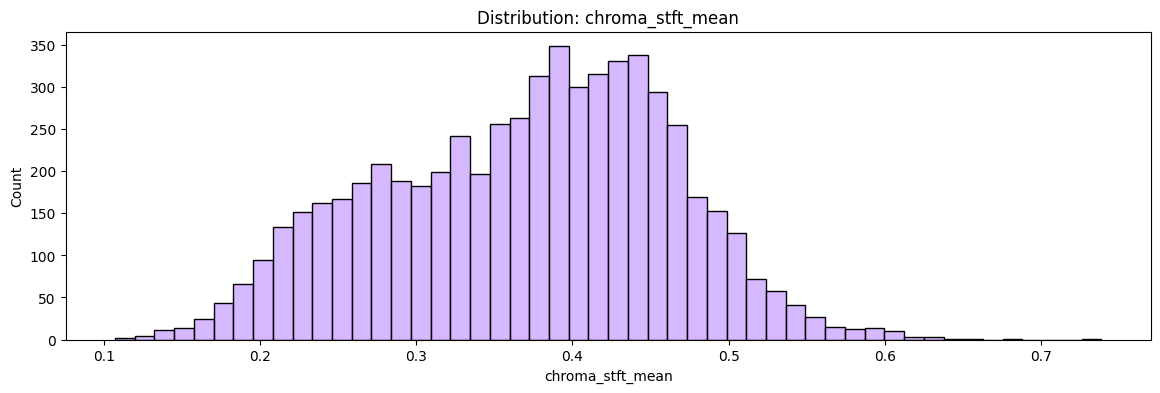

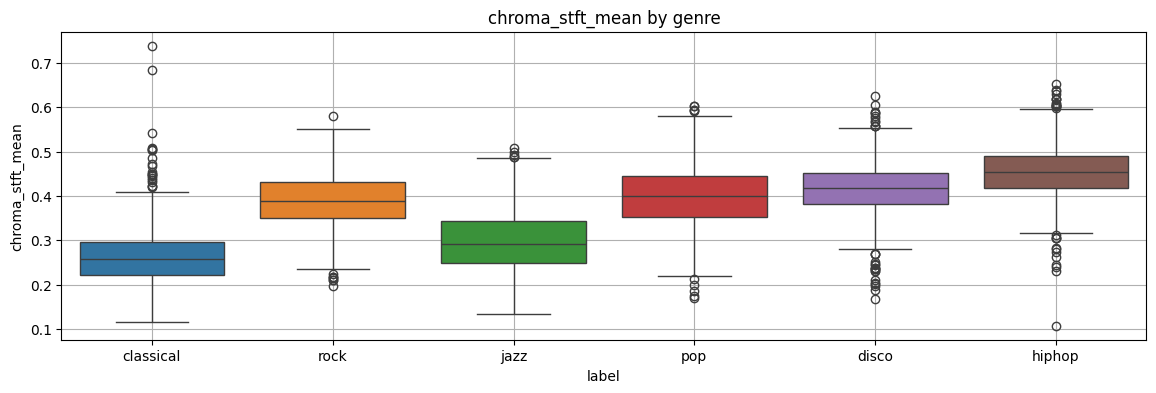

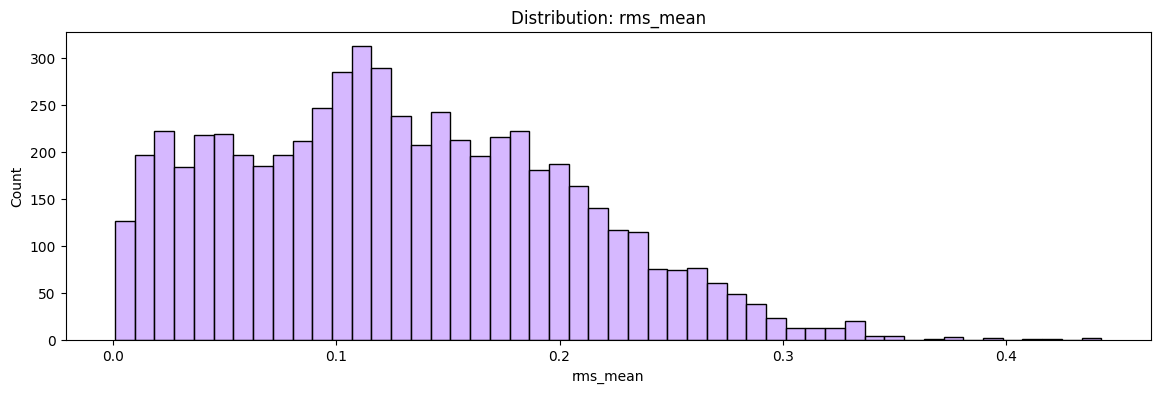

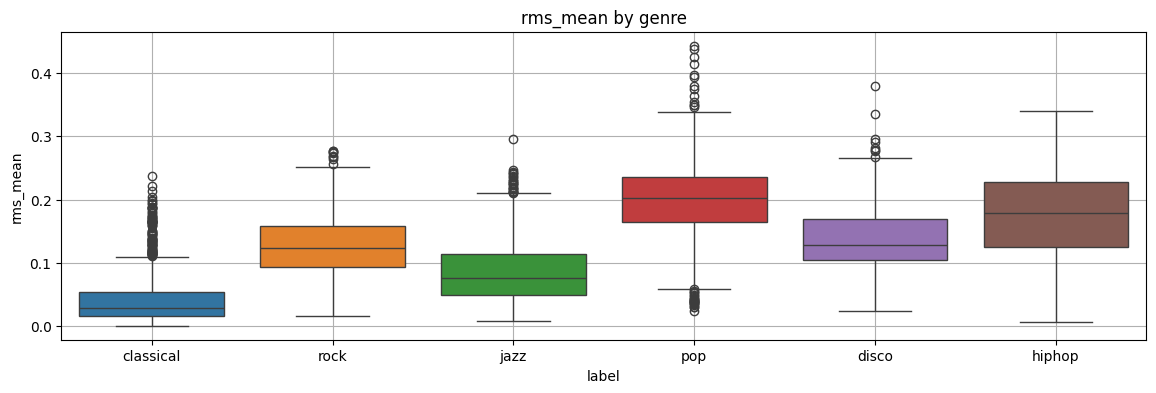

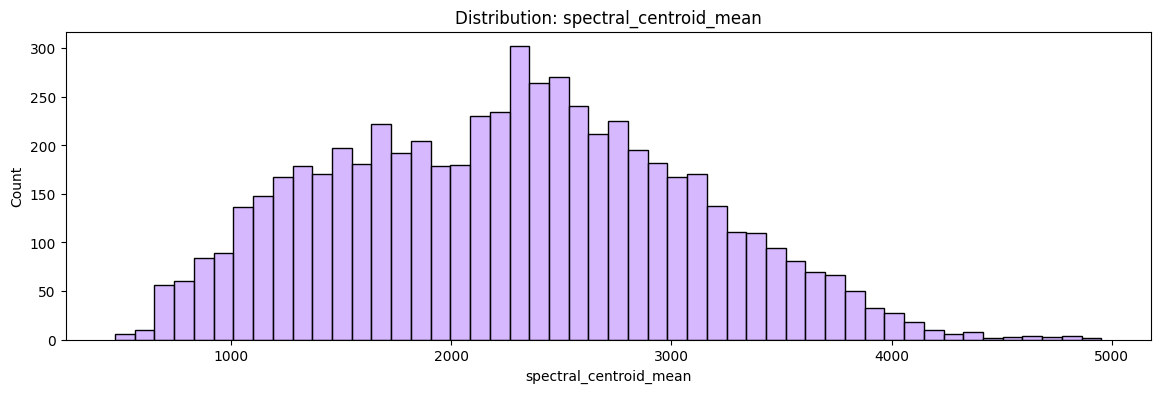

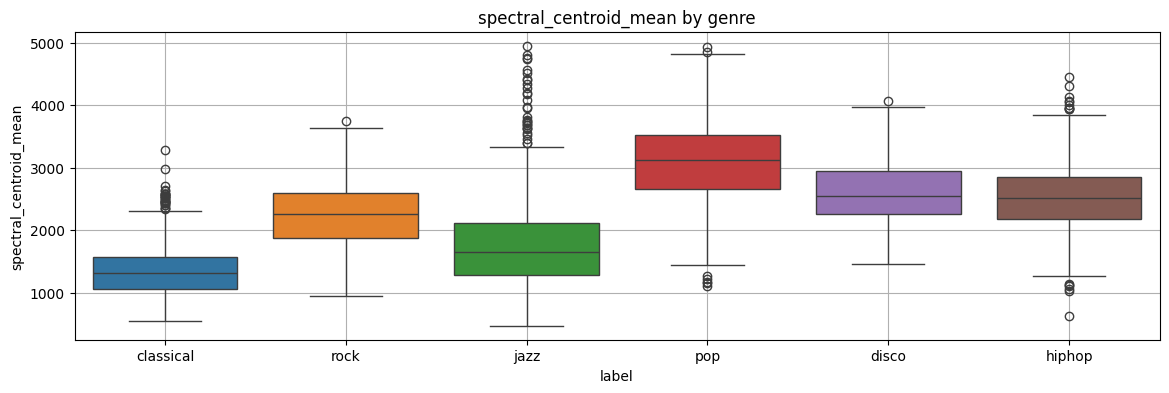

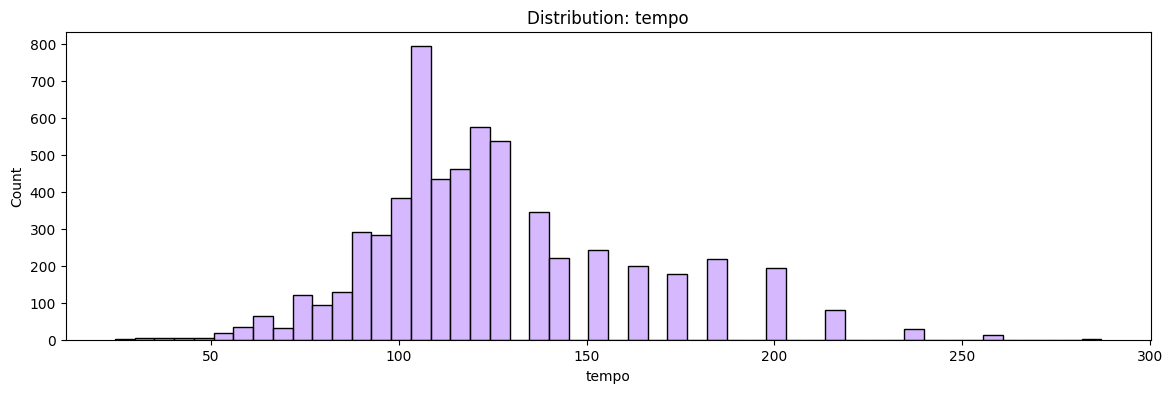

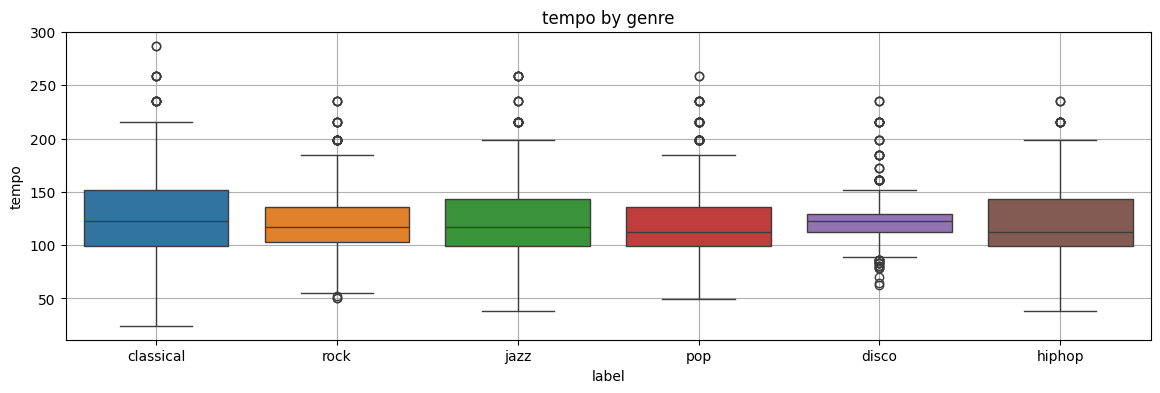

In [4]:
df.describe()
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
numeric_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo"]

for col in numeric_cols:
    plt.figure(figsize=(14, 4))
    sns.histplot(data=df, x=col, bins=50, color="#C9A0FF")
    plt.title(f"Distribution: {col}")
    plt.show()
    plt.figure(figsize=(14, 4))
    sns.boxplot(data=df, y=col, x="label", hue="label")
    plt.title(f"{col} by genre")
    plt.grid()
    plt.show()
